# 1. Dataset visualization and variable types

Inspect dataset dimensions, sample rows, missingness, and column types. Add exploratory visualizations and observations below.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional visualization style
sns.set_theme(style="whitegrid", palette="muted")

# Load newly cleaned dataset
df = pd.read_csv(r'C:\Users\USER\OneDrive - Cambodia Academy of Digital Technology\Car_Sale_Analysis\car_price_prediction\Car_Sale_Analysis\data\raw\final_destination.csv')

# Verify dimensions and clean status
print("Dataset Shape:", df.shape)
print("\nMissing Values Check:\n", df.isnull().sum())
df.head()

Dataset Shape: (15229, 15)

Missing Values Check:
 model                         0
vehicle_age                   0
km_driven                     0
seller_type                   0
transmission_type             0
mileage                       0
engine                        0
max_power                     0
selling_price                 0
real_typical_owner_type       0
real_avg_owner_count          0
real_common_trim              0
real_new_ex_showroom_price    0
real_body_type                0
model_grouped                 0
dtype: int64


,model,vehicle_age,km_driven,seller_type,transmission_type,mileage,engine,max_power,selling_price,real_typical_owner_type,real_avg_owner_count,real_common_trim,real_new_ex_showroom_price,real_body_type,model_grouped
0,Alto,9,120000,Individual,Manual,19.70,796,46.30,120000,First,1.15,LXi,0.519500,Unknown,Alto
1,Grand,5,20000,Individual,Manual,18.90,1197,82.00,550000,First,1.08,i10 Sportz,0.641574,Hatchback,Grand
2,i20,11,60000,Individual,Manual,17.00,1197,80.00,215000,First,1.18,1.2 Magna,0.820343,Hatchback,i20
3,Alto,9,37000,Individual,Manual,20.92,998,67.10,226000,First,1.15,LXi,0.519500,Unknown,Alto
4,Ecosport,6,30000,Dealer,Manual,22.77,1498,98.59,570000,First,1.08,1.5 DV5 MT Titanium Optional,0.856000,SUV,Ecosport


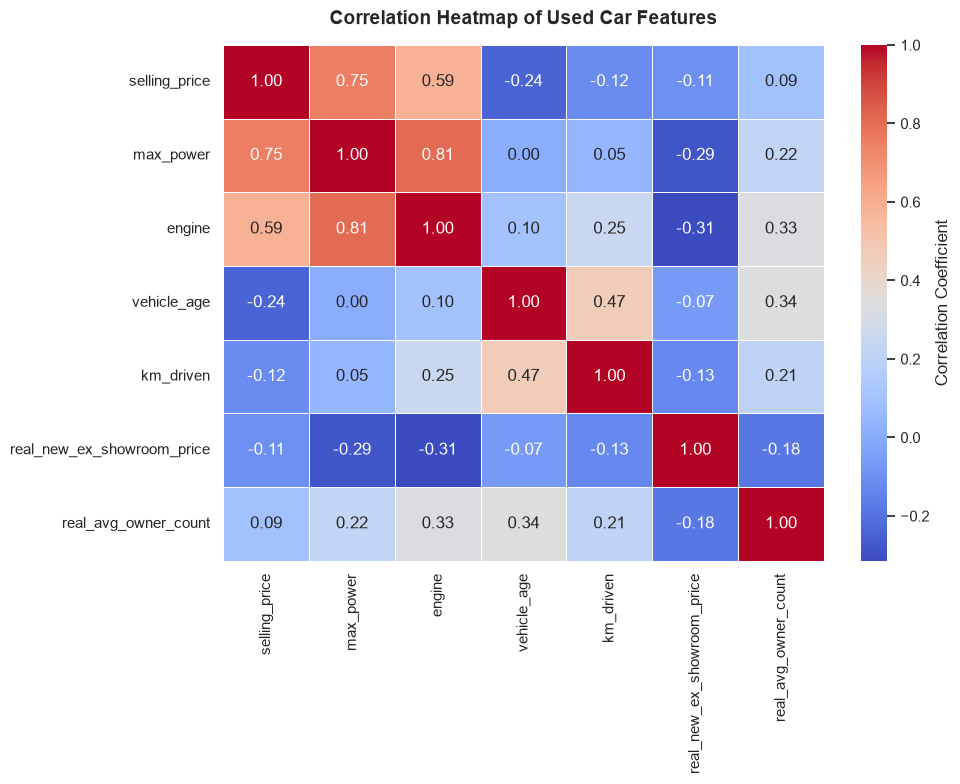

In [8]:
# Select numerical columns for correlation
num_cols = ['selling_price', 'max_power', 'engine', 'vehicle_age', 'km_driven', 'real_new_ex_showroom_price', 'real_avg_owner_count']
corr_matrix = df[num_cols].corr()

# Plotting Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Correlation Heatmap of Used Car Features', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

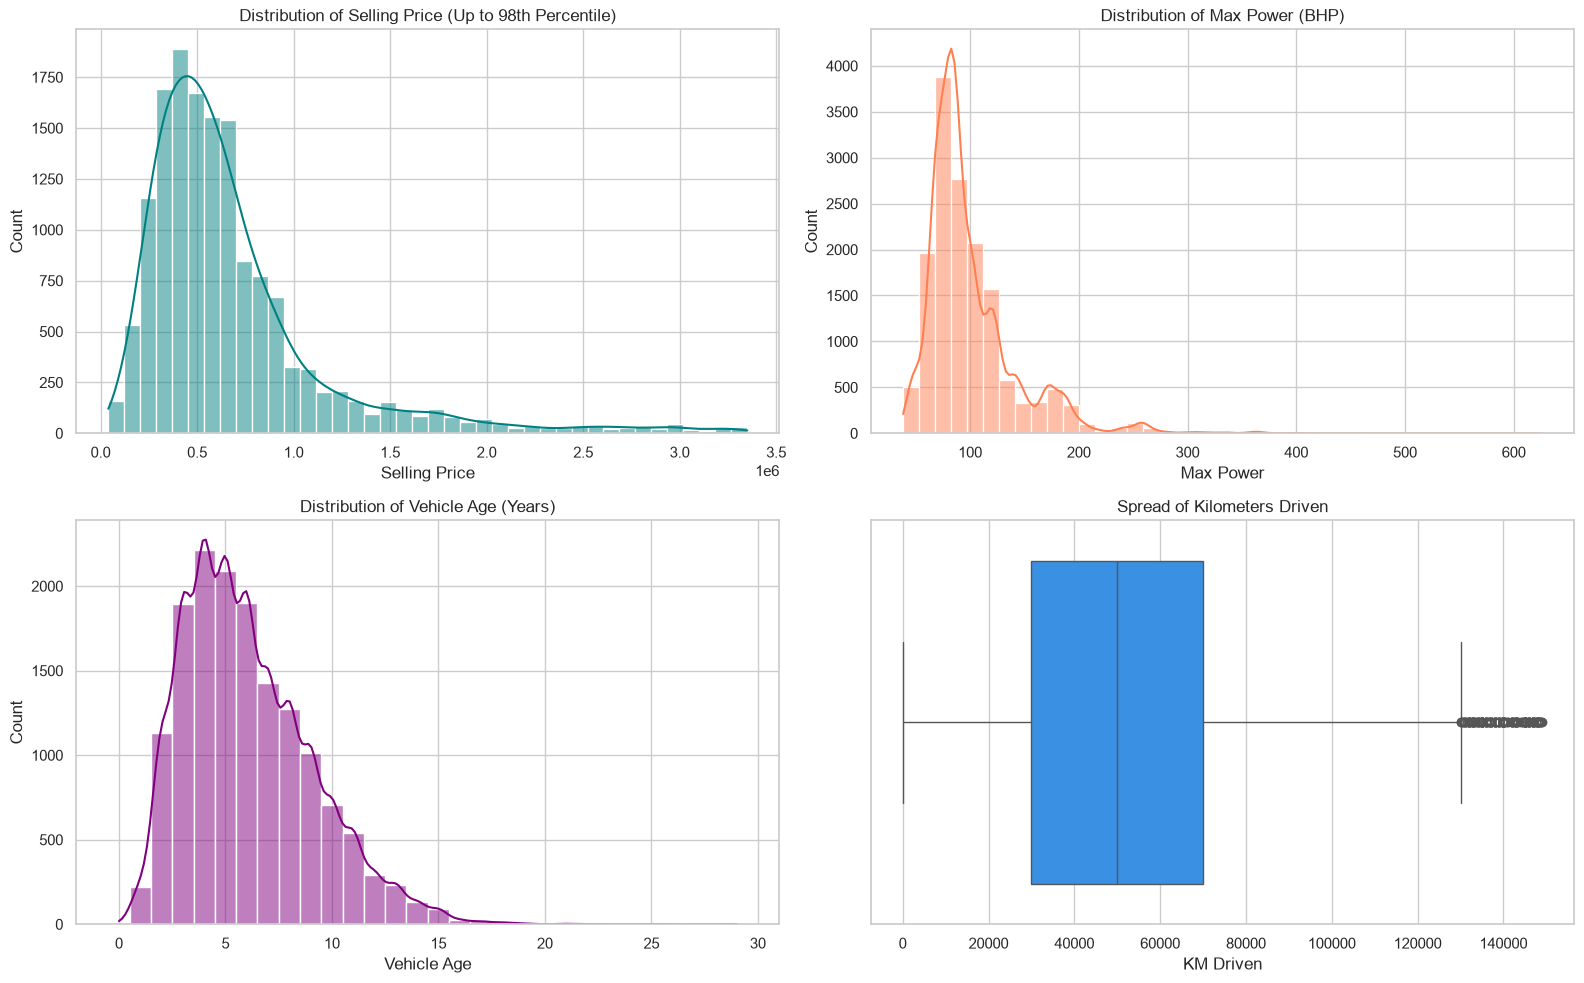

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Selling Price Distribution (trimmed at 98th percentile for readable visualization)
price_cap = df['selling_price'].quantile(0.98)
sns.histplot(df[df['selling_price'] <= price_cap]['selling_price'], kde=True, ax=axes[0, 0], color='teal', bins=40)
axes[0, 0].set_title('Distribution of Selling Price (Up to 98th Percentile)')
axes[0, 0].set_xlabel('Selling Price')

# 2. Max Power Distribution
sns.histplot(df['max_power'], kde=True, ax=axes[0, 1], color='coral', bins=40)
axes[0, 1].set_title('Distribution of Max Power (BHP)')
axes[0, 1].set_xlabel('Max Power')

# 3. Vehicle Age Distribution
sns.histplot(df['vehicle_age'], kde=True, ax=axes[1, 0], color='purple', discrete=True)
axes[1, 0].set_title('Distribution of Vehicle Age (Years)')
axes[1, 0].set_xlabel('Vehicle Age')

# 4. Kilometers Driven Box Plot (trimmed outliers for better scaling)
km_cap = df['km_driven'].quantile(0.98)
sns.boxplot(x=df[df['km_driven'] <= km_cap]['km_driven'], ax=axes[1, 1], color='dodgerblue')
axes[1, 1].set_title('Spread of Kilometers Driven')
axes[1, 1].set_xlabel('KM Driven')

plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_21496\363185644.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='transmission_type', order=df['transmission_type'].value_counts().index, ax=axes[0, 0], palette='Set2')
C:\Users\USER\AppData\Local\Temp\ipykernel_21496\363185644.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='seller_type', order=df['seller_type'].value_counts().index, ax=axes[0, 1], palette='crest')
C:\Users\USER\AppData\Local\Temp\ipykernel_21496\363185644.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sn

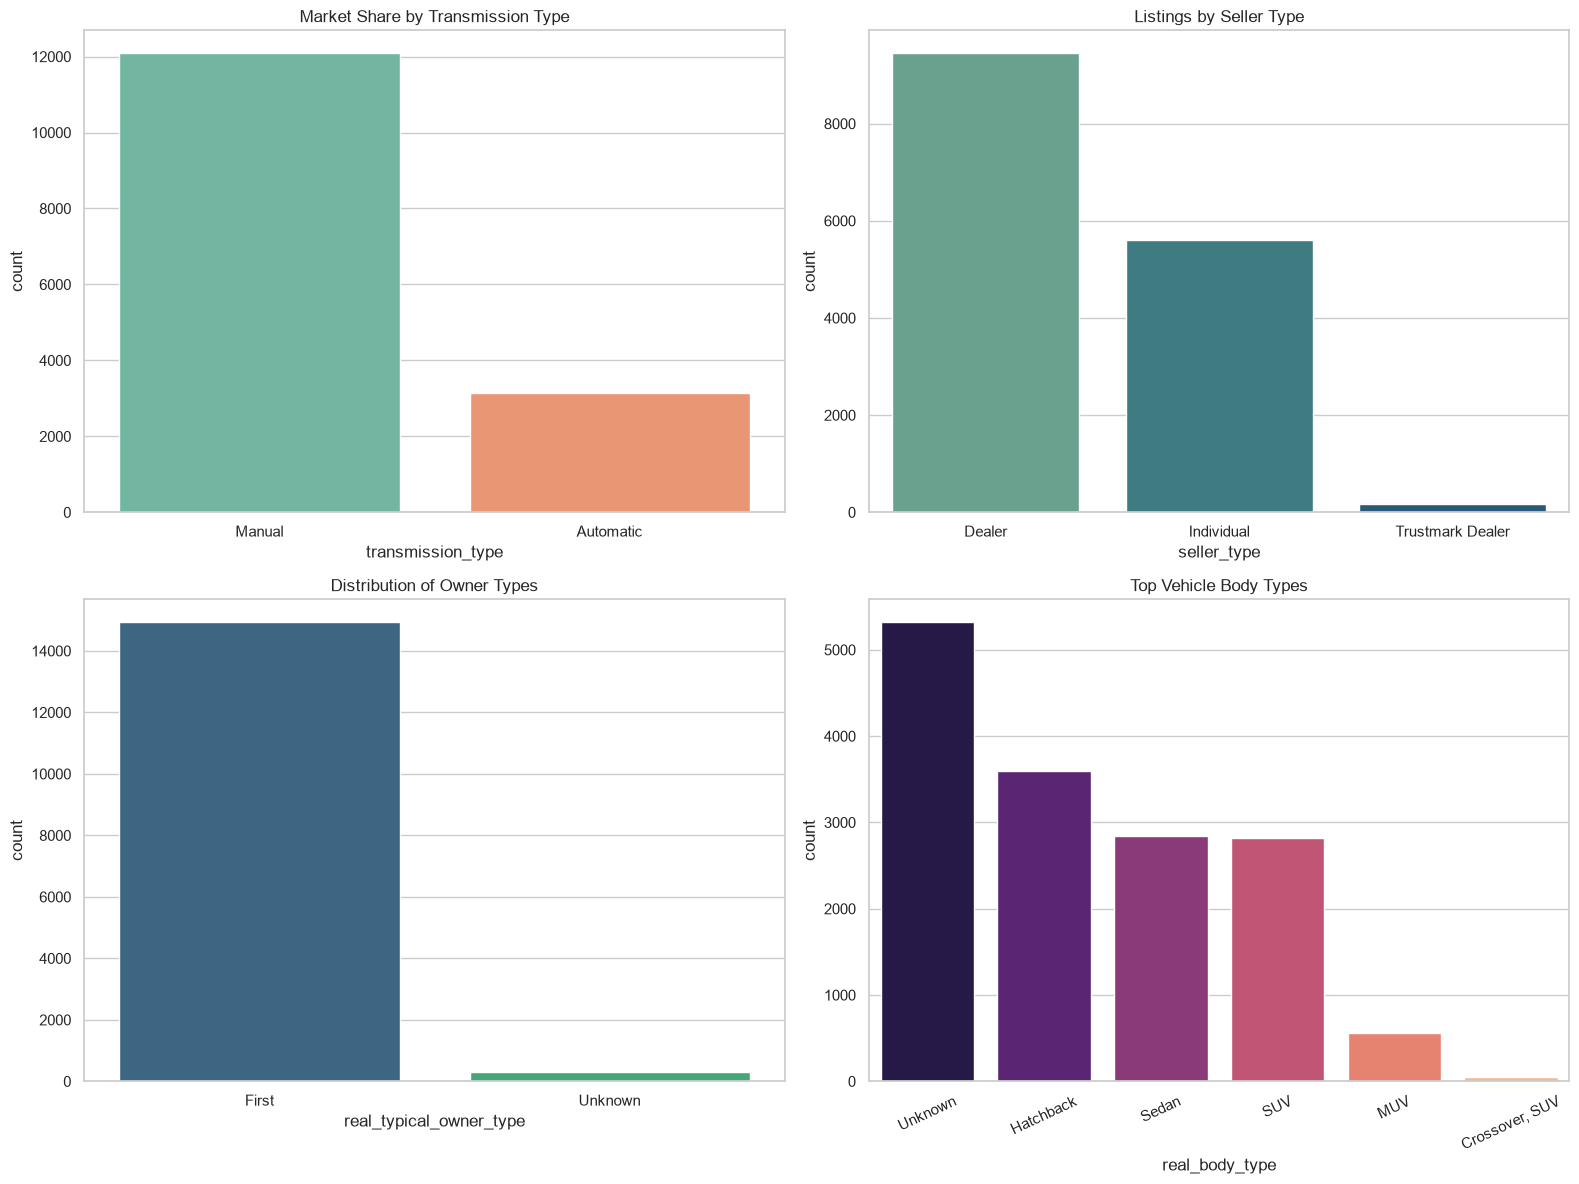

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Transmission Type
sns.countplot(data=df, x='transmission_type', order=df['transmission_type'].value_counts().index, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Market Share by Transmission Type')

# 2. Seller Type
sns.countplot(data=df, x='seller_type', order=df['seller_type'].value_counts().index, ax=axes[0, 1], palette='crest')
axes[0, 1].set_title('Listings by Seller Type')

# 3. Typical Owner Type
sns.countplot(data=df, x='real_typical_owner_type', order=df['real_typical_owner_type'].value_counts().index, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Distribution of Owner Types')

# 4. Top Body Types
top_bodies = df['real_body_type'].value_counts().index[:6]
sns.countplot(data=df, x='real_body_type', order=top_bodies, ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('Top Vehicle Body Types')
axes[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

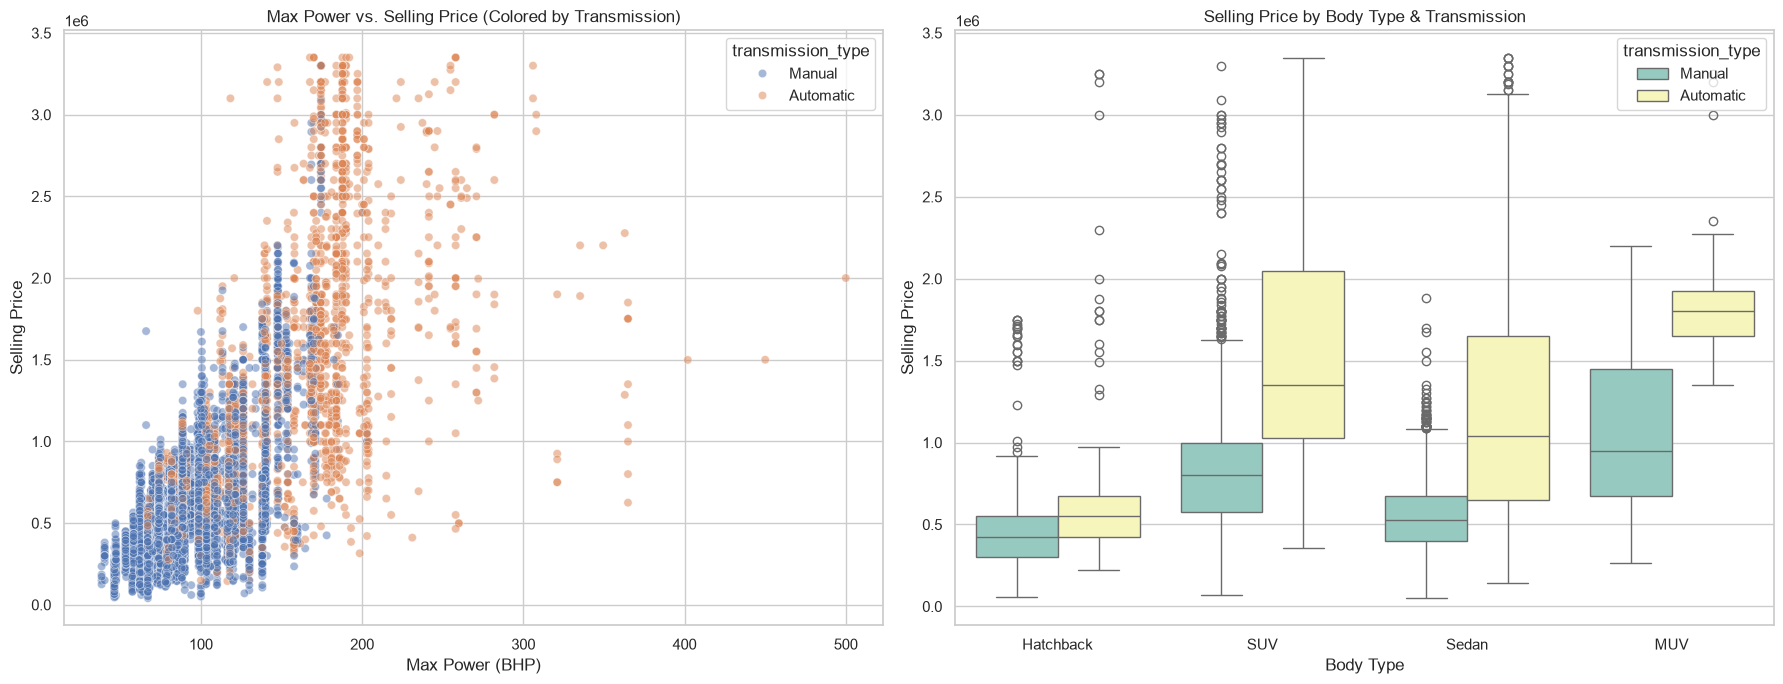

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Max Power vs Selling Price grouped by Transmission Type
sns.scatterplot(
    data=df[df['selling_price'] <= price_cap], 
    x='max_power', 
    y='selling_price', 
    hue='transmission_type', 
    alpha=0.5, 
    ax=axes[0], 
    palette='deep'
)
axes[0].set_title('Max Power vs. Selling Price (Colored by Transmission)')
axes[0].set_xlabel('Max Power (BHP)')
axes[0].set_ylabel('Selling Price')

# 2. Selling Price across Vehicle Age and Body Type (Boxplot)
top_body_df = df[df['real_body_type'].isin(['Hatchback', 'Sedan', 'SUV', 'MUV']) & (df['selling_price'] <= price_cap)]
sns.boxplot(
    data=top_body_df, 
    x='real_body_type', 
    y='selling_price', 
    hue='transmission_type', 
    ax=axes[1], 
    palette='Set3'
)
axes[1].set_title('Selling Price by Body Type & Transmission')
axes[1].set_xlabel('Body Type')
axes[1].set_ylabel('Selling Price')

plt.tight_layout()
plt.show()